## Instructions

The first few code blocks contain the necessary code to run the models, as well as pre-processing steps. These include importing the necessary packages, reading the CSV file, splitting the data, defining the features and target variable, and defining the regression metrics function.

Following the initial setup, the subsequent blocks of code explore various models in a logical order, starting from linear models (such as linear, lasso, polynomial, etc.), followed by nonlinear models (such as XG Boost, Random Forest,etc). Each model is explored using pipelines, allowing for certain preprocessing steps like scaling and imputation to be integrated into the model definition. Hyperparameter optimization is also included within each the respective models' block.  Each model produces a DataFrame containing metric information like the MAE, MSE, Max_Error and R^2 values, allowing for performance evaluation.

Block #8 produces a summary DataFrame that compares the predictive performance of all models. The best three-performing models, XG Boost, Kernel Ridge Regression and K Nearest Neighbours, were then combined into a custom ensemble model. 

Parity plots are generated for the baseline DummyRegressor models and the top performing models. The final block contains a summary table that provides metric information for all tested models, including the custom ensemble model



In [ ]:
'''
Models trained and evaluated on clean_data.csv with 
all NaN values imputed using median imputation.
'''

# 0. Programming Environment Setup
'''
Models trained and evaluated on clean_data.csv with 
all NaN values imputed using median imputation.
'''

# Numerical computing and data handling
import numpy as np
import pandas as pd
from pathlib import Path

# Modelling
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import max_error, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Lasso
from math import degrees
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor


# Dummy modelling
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    max_error,
    mean_absolute_percentage_error,
    root_mean_squared_error
)


# Plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline


In [4]:
#1.1 Data Preparation Part 1

#Fix Random Seed
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)



#drop features, use eda_df since we're using a pipeline that will impute missing values
DATA_DIR = Path.cwd().parent / "EDA"
INPUT_FILE = DATA_DIR / "cleaned_data.csv"

eda_df = pd.read_csv(INPUT_FILE, keep_default_na=False, na_values=[""])
eda_df = eda_df.drop(columns=['Z', 'N'])
eda_df.head(10)

,element,A,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
0,H,3,2.000000,18.5906,NaN,6257.233,NaN,8.589715
1,HE,6,2.000000,3505.2200,NaN,1710.000,NaN,-0.093288
2,BE,7,0.750000,NaN,-1587.13,10677.000,5606.85,6.662589
3,HE,8,3.000000,10663.8800,NaN,2535.000,NaN,-0.924088
4,LI,8,1.666667,16004.1300,NaN,2032.620,12416.00,-0.075772
5,B,8,0.600000,-12143.0000,NaN,NaN,136.40,-0.113509
6,LI,9,2.000000,13606.4500,NaN,4062.220,13943.75,-0.748849
7,C,9,0.500000,NaN,-10650.00,14225.000,1299.60,-0.897909
8,C,10,0.666667,NaN,-5101.00,21283.500,4006.70,1.285332
9,LI,11,2.666667,20551.1000,NaN,396.000,NaN,-2.057992


In [3]:
#1.2 Data Preparation Part 2

#splitting: uses a random split since the data is not skewed 
df_train, df_test = train_test_split(
    eda_df,
    test_size=0.2,  # 20% for testing
    random_state= RANDOM_SEED  # Ensure reproducibility
)
print(df_train.shape)
df_train.head()

#Define features
features = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

#Define target
TARGET = df_train['log_half_life'].name

#Regression metrics function from tutorial 4
def get_regression_metrics(model, X, y_true):

    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)
    rmse = root_mean_squared_error(y_true, y_predicted)

    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'max_error': maximum_error,
        'rmse': rmse,
        'r^2': r2_score(y_true, y_predicted)
    }

    return metrics_dict

(2236, 8)


In [4]:
#2.1 Build Baseline Model  (Mean)

#baseline model using a mean dummy regressor 
dummyregressor_mean = make_pipeline(
    SimpleImputer(strategy='median'),
    DummyRegressor(strategy='mean')
)

dummyregressor_mean.fit(df_train[features], df_train[TARGET])

dummyregressor_mean_results_train = get_regression_metrics(
    dummyregressor_mean,
    df_train[features],
    df_train[TARGET]
)

# Testing results
dummyregressor_mean_results_test = get_regression_metrics(
    dummyregressor_mean,
    df_test[features],
    df_test[TARGET]
)

# Create dataframe
dummyregressor_mean_results_df = pd.DataFrame(
    [dummyregressor_mean_results_train, dummyregressor_mean_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
dummyregressor_mean_results_df = dummyregressor_mean_results_df.round(4)

# Display dataframe
display(dummyregressor_mean_results_df)

,mae,mse,max_error,rmse,r^2
Train,2.4258,10.3292,20.4711,3.2139,0.0
Test,2.3584,10.0656,12.4807,3.1726,-0.0


In [5]:
#2.2 Build baseline model using a median dummy regressor 
dummyregressor_median = make_pipeline(
    SimpleImputer(strategy='median'),
    DummyRegressor(strategy='median')
)

dummyregressor_median.fit(df_train[features], df_train[TARGET])

dummyregressor_median_results_train = get_regression_metrics(
    dummyregressor_median,
    df_train[features],
    df_train[TARGET]
)

# Testing results
dummyregressor_median_results_test = get_regression_metrics(
    dummyregressor_median,
    df_test[features],
    df_test[TARGET]
)

# Create dataframe
dummyregressor_median_results_df = pd.DataFrame(
    [dummyregressor_median_results_train, dummyregressor_median_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
dummyregressor_median_results_df = dummyregressor_median_results_df.round(4)

# Display dataframe
display(dummyregressor_median_results_df)

,mae,mse,max_error,rmse,r^2
Train,2.4254,10.3322,20.4171,3.2144,-0.0003
Test,2.3565,10.0667,12.4267,3.1728,-0.0001


In [6]:
#3.1 Linear Regression
linear_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LinearRegression()
)

# Train model
linear_model.fit(df_train[features], df_train[TARGET])

# Calculate metrics
linear_model_results_train = get_regression_metrics(
    linear_model, df_train[features], df_train[TARGET]
)

linear_model_results_test = get_regression_metrics(
    linear_model, df_test[features], df_test[TARGET]
)

# Create dataframe
linear_model_results_df = pd.DataFrame(
    [linear_model_results_train, linear_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
linear_model_results_df = linear_model_results_df.round(4)

# Add model name
linear_model_results_df.insert(0, 'Model', 'Linear Regression')

# Display dataframe
display(linear_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Linear Regression,2.2655,9.4157,21.8638,3.0685,0.0884
Test,Linear Regression,2.1944,9.1955,12.7089,3.0324,0.0864


In [7]:
#3.2 Ridge Regression
ridge_model = make_pipeline(
    SimpleImputer(strategy=('median')),
    StandardScaler(),
    Ridge(alpha=1.0)
)
ridge_model.fit(df_train[features],df_train[TARGET])
ridge_model_results_train = get_regression_metrics(ridge_model, df_train[features], df_train[TARGET])
ridge_model_results_test = get_regression_metrics(ridge_model, df_test[features], df_test[TARGET])

# Create dataframe
ridge_model_results_df = pd.DataFrame(
    [ridge_model_results_train, ridge_model_results_test],
    index=['Train', 'Test'])

# Round to 4 decimal places
ridge_model_results_df = ridge_model_results_df.round(4)
ridge_model_results_df.insert(0, 'Model', 'Ridge Regression')

# Display dataframe
display(ridge_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Ridge Regression,2.2654,9.4157,21.8599,3.0685,0.0884
Test,Ridge Regression,2.1944,9.1954,12.7085,3.0324,0.0864


In [8]:
#3.3 LASSO 
lasso_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=10000)
)

lasso_model.fit(df_train[features],df_train[TARGET])
lasso_model_results_train = get_regression_metrics(lasso_model, df_train[features], df_train[TARGET])
lasso_model_results_test = get_regression_metrics(lasso_model, df_test[features], df_test[TARGET])

lasso_model_results_df = pd.DataFrame(
    [lasso_model_results_train, lasso_model_results_test],
    index=['Train', 'Test']
)
# Round to 4 decimal places
lasso_model_results_df = lasso_model_results_df.round(4)
lasso_model_results_df.insert(0, 'Model', 'Lasso Regression')

# Display dataframe
display(lasso_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Lasso Regression,2.2972,9.6245,21.0340,3.1023,0.0682
Test,Lasso Regression,2.2164,9.3912,13.0417,3.0645,0.0670


In [9]:
#3.4 Polynomial Models Part 1
polynomial_results = []

for degree in [2,3,4]: #testing various polynomial degrees
    polynomial_model = make_pipeline(
        SimpleImputer(strategy='median'),
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    polynomial_model.fit(df_train[features],df_train[TARGET])
    polynomial_model_results_train = get_regression_metrics(polynomial_model, df_train[features], df_train[TARGET])
    polynomial_model_results_test = get_regression_metrics(polynomial_model, df_test[features], df_test[TARGET])

    polynomial_results.append({
    "Degree": degree,

    **{f"Train {k.upper()}": v
       for k, v in polynomial_model_results_train.items()},

    **{f"Test {k.upper()}": v
       for k, v in polynomial_model_results_test.items()}
})


polynomial_results_df = pd.DataFrame(polynomial_results)

polynomial_results_df = polynomial_results_df.copy()

# Rename and organize columns into Train and Test groups
polynomial_results_df = polynomial_results_df.set_index('Degree')

polynomial_results_df = polynomial_results_df[
    [
        'Train MAE', 'Train MSE', 'Train RMSE',
        'Train R^2', 'Train MAX_ERROR',
        'Test MAE', 'Test MSE', 'Test RMSE',
        'Test R^2', 'Test MAX_ERROR'
    ]
]

# Create grouped column headings
polynomial_results_df.columns = pd.MultiIndex.from_tuples([
    ('Train', 'MAE'),
    ('Train', 'MSE'),
    ('Train', 'RMSE'),
    ('Train', 'R²'),
    ('Train', 'Max Error'),
    ('Test', 'MAE'),
    ('Test', 'MSE'),
    ('Test', 'RMSE'),
    ('Test', 'R²'),
    ('Test', 'Max Error')
])

# Round values
polynomial_results_df = polynomial_results_df.round(4)

display(polynomial_results_df)

Train                                      Test                      \
           MAE     MSE    RMSE      R² Max Error     MAE        MSE     RMSE   
Degree                                                                         
2       1.8393  6.6252  2.5739  0.3586   11.8365  1.7963     7.0192   2.6494   
3       1.4078  4.2337  2.0576  0.5901    9.2258  1.5361     6.0806   2.4659   
4       1.1401  2.7313  1.6527  0.7356    9.0472  3.6313  2320.4906  48.1715   

                             
              R²  Max Error  
Degree                       
2         0.3026     9.8753  
3         0.3959    15.7606  
4      -229.5427  1133.6990

In [10]:
#3.5 using a polynomial model with degree 3
polynomial_deg3_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

polynomial_deg3_model.fit(df_train[features],df_train[TARGET])
polynomial_deg3_results_train = get_regression_metrics(polynomial_deg3_model, df_train[features], df_train[TARGET])
polynomial_deg3_results_test = get_regression_metrics(polynomial_deg3_model, df_test[features], df_test[TARGET])

polynomial_deg3_results_df = pd.DataFrame(
    [polynomial_deg3_results_train, polynomial_deg3_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
polynomial_deg3_results_df = polynomial_deg3_results_df.round(4)
polynomial_deg3_results_df.insert(0, 'Model', 'Polynomial (3rd Degree)')

# Display dataframe
display(polynomial_deg3_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Polynomial (3rd Degree),1.4078,4.2337,9.2258,2.0576,0.5901
Test,Polynomial (3rd Degree),1.5361,6.0806,15.7606,2.4659,0.3959


In [11]:
#Kernel Ridge Regression Model
krr_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('krr', KernelRidge(
        alpha=1.0,
        kernel='rbf',
        gamma=0.1
    ))
])

#Train baseline model
krr_baseline.fit(df_train[features], df_train[TARGET])

#Define hyperparameter grid
krr_param_grid = {
    'scaling': [StandardScaler(), MinMaxScaler()],
    'krr__alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],
    'krr__gamma': [0.001, 0.01, 0.1, 1.0, 10.0]
}


#Optimize KRR using GridSearchCV
grid_krr = GridSearchCV(
    estimator=krr_baseline,
    param_grid=krr_param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

#Fit using training data only
grid_krr.fit(df_train[features], df_train[TARGET])

#Display best hyperparameters
print("Best parameters:", grid_krr.best_params_)
print("Best CV MAE:", -grid_krr.best_score_)


#Retrieve optimized KRR model
krr_optimized = grid_krr.best_estimator_


#Evaluate baseline and optimized models

#Baseline model metrics
krr_baseline_results_train = get_regression_metrics(
    krr_baseline, df_train[features], df_train[TARGET]
)

krr_baseline_results_test = get_regression_metrics(
    krr_baseline, df_test[features], df_test[TARGET]
)

# Optimized model metrics
krr_optimized_results_train = get_regression_metrics(
    krr_optimized, df_train[features], df_train[TARGET]
)

krr_optimized_results_test = get_regression_metrics(
    krr_optimized, df_test[features], df_test[TARGET]
)


#Create comparison DataFrame
#Create comparison DataFrames
df_krr_train_results = pd.DataFrame.from_dict(
    {
        'KRR - Baseline': krr_baseline_results_train,
        'KRR - Optimized': krr_optimized_results_train
    },
    orient='index'
)

df_krr_test_results = pd.DataFrame.from_dict(
    {
        'KRR - Baseline': krr_baseline_results_test,
        'KRR - Optimized': krr_optimized_results_test
    },
    orient='index'
)

#Combine training and testing results side-by-side
df_krr_comparison = pd.concat(
    {
        'Train': df_krr_train_results,
        'Test': df_krr_test_results
    },
    axis=1
)

df_krr_comparison.index.name = 'Model'

#Display results
print("\nComparison of Kernel Ridge Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_krr_comparison.round(4))


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters: {'krr__alpha': 0.1, 'krr__gamma': 1.0, 'scaling': StandardScaler()}
Best CV MAE: 1.0159898735024555

Comparison of Kernel Ridge Regression Model Performance



Train                                      Test                                  
                    mae     mse max_error    rmse     r^2     mae     mse max_error    rmse     r^2
Model                                                                                              
KRR - Baseline   1.3139  3.9801   11.8370  1.9950  0.6147  1.3304  4.4326    9.9756  2.1054  0.5596
KRR - Optimized  0.6708  1.0812    8.2907  1.0398  0.8953  0.9157  2.1241   11.3042  1.4574  0.7890

In [12]:
#5. XGBoost 

#Train baseline model
xgb_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('xgb', XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_SEED
    ))
])

xgb_baseline.fit(df_train[features], df_train[TARGET])

xgb_param_grid = {
    'scaling': [StandardScaler(), MinMaxScaler()],
    'xgb__n_estimators': [100, 200, 300],
    'xgb__learning_rate': [0.01, 0.05, 0.1],
    'xgb__max_depth': [2, 3, 5]
}

grid_xgb = GridSearchCV(
    estimator=xgb_baseline,
    param_grid=xgb_param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    verbose=1
)


#Define hyperparameter grid

#Optimize KRR using GridSearchCV
#Fit using training data only
xgb_param_grid = {
    'scaling': [StandardScaler(), MinMaxScaler()],
    'xgb__n_estimators': [100, 200, 300],
    'xgb__learning_rate': [0.01, 0.05, 0.1],
    'xgb__max_depth': [2, 3, 5]
}

grid_xgb = GridSearchCV(
    estimator=xgb_baseline,
    param_grid=xgb_param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    verbose=1
)

grid_xgb.fit(df_train[features], df_train[TARGET])

# Display best hyperparameters
print("Best parameters:", grid_xgb.best_params_)
print("Best CV MAE:", -grid_xgb.best_score_)


#Retrieve optimized KRR model

xgb_optimized = grid_xgb.best_estimator_


#Evaluate baseline and optimized models

#Baseline model metrics
xgb_baseline_results_train = get_regression_metrics(
    xgb_baseline, df_train[features], df_train[TARGET]
)

xgb_baseline_results_test = get_regression_metrics(
    xgb_baseline, df_test[features], df_test[TARGET]
)

#Optimized model metrics
xgb_optimized_results_train = get_regression_metrics(
    xgb_optimized, df_train[features], df_train[TARGET]
)

xgb_optimized_results_test = get_regression_metrics(
    xgb_optimized, df_test[features], df_test[TARGET]
)


#Create comparison DataFrame
df_xgb_train_results = pd.DataFrame.from_dict(
    {
        'XGB - Baseline': xgb_baseline_results_train,
        'XGB - Optimized': xgb_optimized_results_train
    },
    orient='index'
)

df_xgb_test_results = pd.DataFrame.from_dict(
    {
        'XGB - Baseline': xgb_baseline_results_test,
        'XGB - Optimized': xgb_optimized_results_test
    },
    orient='index'
)

# Combine training and testing results side-by-side
df_xgb_comparison = pd.concat(
    {
        'Train': df_xgb_train_results,
        'Test': df_xgb_test_results
    },
    axis=1
)

df_xgb_comparison.index.name = 'Model'

# Display results
print("\nComparison of XGBoost Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_xgb_comparison.round(4))
    


Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters: {'scaling': StandardScaler(), 'xgb__learning_rate': 0.1, 'xgb__max_depth': 5, 'xgb__n_estimators': 300}
Best CV MAE: 0.9481939924525701

Comparison of XGBoost Performance



Train                                      Test                                  
                    mae     mse max_error    rmse     r^2     mae     mse max_error    rmse     r^2
Model                                                                                              
XGB - Baseline   1.0068  2.0759   10.7132  1.4408  0.7990  1.0809  2.5595    6.7715  1.5999  0.7457
XGB - Optimized  0.3346  0.2305    3.3457  0.4801  0.9777  0.8559  1.7255    7.6070  1.3136  0.8286

In [13]:
#6. Random Forest Model

# Train baseline model
rf_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('rf', RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=RANDOM_SEED
    ))
])

rf_baseline.fit(df_train[features], df_train[TARGET])

param_grid_rf = {
    'randomforestregressor__n_estimators': [100, 200, 300],
    'randomforestregressor__max_depth': [None, 10, 20, 30],
    'randomforestregressor__min_samples_split': [2, 5, 10],
    'randomforestregressor__min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator=rf_baseline,
    param_grid=param_grid_rf,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)


rf_baseline.fit(df_train[features], df_train[TARGET])

param_grid_rf = {
    'rf__n_estimators': [100, 200, 300],
    'rf__max_depth': [None, 10, 20, 30],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator=rf_baseline,
    param_grid=param_grid_rf,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(
    df_train[features],
    df_train[TARGET]
)

# Display best hyperparameters
print("Best parameters:", grid_rf.best_params_)
print("Best CV MAE:", -grid_rf.best_score_)


# 4. Retrieve optimized KRR model

rf_optimized = grid_rf.best_estimator_


# 5. Evaluate baseline and optimized models

# Baseline model metrics
rf_baseline_results_train = get_regression_metrics(
    rf_baseline, df_train[features], df_train[TARGET]
)

rf_baseline_results_test = get_regression_metrics(
    rf_baseline, df_test[features], df_test[TARGET]
)

# Optimized model metrics
rf_optimized_results_train = get_regression_metrics(
    rf_optimized, df_train[features], df_train[TARGET]
)

rf_optimized_results_test = get_regression_metrics(
    rf_optimized, df_test[features], df_test[TARGET]
)


# 6. Create comparison DataFrame
df_rf_train_results = pd.DataFrame.from_dict(
    {
        'Random Forest - Baseline': rf_baseline_results_train,
        'Random Forest - Optimized': rf_optimized_results_train
    },
    orient='index'
)

df_rf_test_results = pd.DataFrame.from_dict(
    {
        'Random Forest - Baseline': rf_baseline_results_test,
        'Random Forest - Optimized': rf_optimized_results_test
    },
    orient='index'
)

# Combine training and testing results side-by-side
df_rf_comparison = pd.concat(
    {
        'Train': df_rf_train_results,
        'Test': df_rf_test_results
    },
    axis=1
)

df_rf_comparison.index.name = 'Model'

# Display results
print("\nComparison of Random Forest Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_rf_comparison.round(4))
    

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'rf__max_depth': 20, 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 2, 'rf__n_estimators': 200}
Best CV MAE: 0.9587425425301209

Comparison of Random Forest Performance



Train                                      Test                                  
                              mae     mse max_error    rmse     r^2     mae     mse max_error    rmse     r^2
Model                                                                                                        
Random Forest - Baseline   0.3438  0.3010    5.7374  0.5486  0.9709  0.8455  1.8744    7.9529  1.3691  0.8138
Random Forest - Optimized  0.3476  0.3036    5.7430  0.5510  0.9706  0.8461  1.8712    8.1606  1.3679  0.8141

In [14]:
#7. K-Nearest Neighbours Model

knn_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('knn', KNeighborsRegressor(
        n_neighbors=5
    ))
])

# Train baseline model
knn_baseline.fit(df_train[features], df_train[TARGET])


#Define hyperparameter grid
param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

#Optimize KNN using GridSearchCV

grid_knn = GridSearchCV(
    estimator=knn_baseline,
    param_grid=param_grid_knn,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_knn.fit(
    df_train[features],
    df_train[TARGET]
)

#Display best hyperparameters
print("Best parameters:", grid_knn.best_params_)
print("Best CV MAE:", -grid_knn.best_score_)


#Retrieve optimized KNN model

knn_optimized = grid_knn.best_estimator_


# Evaluate baseline and optimized models

# Baseline model metrics
knn_baseline_results_train = get_regression_metrics(
    knn_baseline, df_train[features], df_train[TARGET]
)

knn_baseline_results_test = get_regression_metrics(
    knn_baseline, df_test[features], df_test[TARGET]
)

# Optimized model metrics
knn_optimized_results_train = get_regression_metrics(
    knn_optimized, df_train[features], df_train[TARGET]
)

knn_optimized_results_test = get_regression_metrics(
    knn_optimized, df_test[features], df_test[TARGET]
)


#Create comparison DataFrames

df_knn_train_results = pd.DataFrame.from_dict(
    {
        'KNN - Baseline': knn_baseline_results_train,
        'KNN - Optimized': knn_optimized_results_train
    },
    orient='index'
)

df_knn_test_results = pd.DataFrame.from_dict(
    {
        'KNN - Baseline': knn_baseline_results_test,
        'KNN - Optimized': knn_optimized_results_test
    },
    orient='index'
)

# Combine training and testing results side-by-side
df_knn_comparison = pd.concat(
    {
        'Train': df_knn_train_results,
        'Test': df_knn_test_results
    },
    axis=1
)

df_knn_comparison.index.name = 'Model'


#Display results

print("\nComparison of KNN Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_knn_comparison.round(4))


Fitting 5 folds for each of 28 candidates, totalling 140 fits
Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV MAE: 1.0586758362862458

Comparison of KNN Performance



Train                                      Test                                  
                    mae     mse max_error    rmse     r^2     mae     mse max_error    rmse     r^2
Model                                                                                              
KNN - Baseline   0.8742  1.9497   14.6232  1.3963  0.8112  1.0156  2.5414     9.381  1.5942  0.7475
KNN - Optimized  0.0000  0.0000    0.0000  0.0000  1.0000  1.0006  2.5802     9.386  1.6063  0.7437

In [15]:
#8. Summary Dataframe of all models created so far

# Create dataframe containing all test results
all_results_test_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_test,
    'Dummy (Median)': dummyregressor_median_results_test,
    'OLS - Baseline': linear_model_results_test,
    'Ridge Regression': ridge_model_results_test,
    'LASSO': lasso_model_results_test,
    'Polynomial Degree 3': polynomial_deg3_results_test,
    'Kernel Ridge Regression': krr_optimized_results_test,
    'XGBoost': xgb_optimized_results_test,
    'Random Forest': rf_optimized_results_test,
    'K Nearest Neighbors': knn_optimized_results_test,
})

# Transpose dataframe
all_results_test_df = all_results_test_df.T

# Add model categories
all_results_test_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Tree-Based Regression',
    'Tree-Based Regression',
    'Distance-Based Regression'
])

# Add model names
all_results_test_df.insert(1, 'Model', all_results_test_df.index)

# Reset index
all_results_test_df = all_results_test_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_test_df = all_results_test_df.round(4)


# Display test results
print("\nTEST SET MODEL PERFORMANCE")
display(all_results_test_df)



# Create dataframe containing all training results
all_results_train_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_train,
    'Dummy (Median)': dummyregressor_median_results_train,
    'OLS - Baseline': linear_model_results_train,
    'Ridge Regression': ridge_model_results_train,
    'LASSO': lasso_model_results_train,
    'Polynomial Degree 3': polynomial_deg3_results_train,
    'Kernel Ridge Regression': krr_optimized_results_train,
    'XGBoost': xgb_optimized_results_train,
    'Random Forest': rf_optimized_results_train,
    'K Nearest Neighbors': knn_optimized_results_train,
})

# Transpose dataframe
all_results_train_df = all_results_train_df.T

# Add model categories
all_results_train_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Tree-Based Regression',
    'Tree-Based Regression',
    'Distance-Based Regression'
])

# Add model names
all_results_train_df.insert(1, 'Model', all_results_train_df.index)

# Reset index
all_results_train_df = all_results_train_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_train_df = all_results_train_df.round(4)

# Display results
print("\nTRAINING SET MODEL PERFORMANCE")
display(all_results_train_df)



TEST SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.3584,10.0656,12.4807,3.1726,-0.0000
1,Dummy Regression,Dummy (Median),2.3565,10.0667,12.4267,3.1728,-0.0001
2,Linear Regression,OLS - Baseline,2.1944,9.1955,12.7089,3.0324,0.0864
3,Linear Regression,Ridge Regression,2.1944,9.1954,12.7085,3.0324,0.0864
4,Linear Regression,LASSO,2.2164,9.3912,13.0417,3.0645,0.0670
5,Polynomial Regression,Polynomial Degree 3,1.5361,6.0806,15.7606,2.4659,0.3959
6,Kernel Regression,Kernel Ridge Regression,0.9157,2.1241,11.3042,1.4574,0.7890
7,Tree-Based Regression,XGBoost,0.8559,1.7255,7.6070,1.3136,0.8286
8,Tree-Based Regression,Random Forest,0.8461,1.8712,8.1606,1.3679,0.8141
9,Distance-Based Regression,K Nearest Neighbors,1.0006,2.5802,9.3860,1.6063,0.7437



TRAINING SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.4258,10.3292,20.4711,3.2139,0.0000
1,Dummy Regression,Dummy (Median),2.4254,10.3322,20.4171,3.2144,-0.0003
2,Linear Regression,OLS - Baseline,2.2655,9.4157,21.8638,3.0685,0.0884
3,Linear Regression,Ridge Regression,2.2654,9.4157,21.8599,3.0685,0.0884
4,Linear Regression,LASSO,2.2972,9.6245,21.0340,3.1023,0.0682
5,Polynomial Regression,Polynomial Degree 3,1.4078,4.2337,9.2258,2.0576,0.5901
6,Kernel Regression,Kernel Ridge Regression,0.6708,1.0812,8.2907,1.0398,0.8953
7,Tree-Based Regression,XGBoost,0.3346,0.2305,3.3457,0.4801,0.9777
8,Tree-Based Regression,Random Forest,0.3476,0.3036,5.7430,0.5510,0.9706
9,Distance-Based Regression,K Nearest Neighbors,0.0000,0.0000,0.0000,0.0000,1.0000


In [16]:
#9. Create a custom ensemble model out of the top 3 performing models from first round of testing
# ensemble model = random forest + xgb + krr, all with equal weight
ensemble_model = VotingRegressor(
    estimators=[
        ('random forest', rf_optimized),
        ('xgb', xgb_optimized),
        ('krr', krr_optimized),
    ]
)

ensemble_model.fit(df_train[features], df_train[TARGET])
ensemble_model_results_train = get_regression_metrics(ensemble_model, df_train[features], df_train[TARGET])
ensemble_model_results_test = get_regression_metrics(ensemble_model, df_test[features], df_test[TARGET])

# Create dataframe
ensemble_model_results_df = pd.DataFrame(
    [ensemble_model_results_train, ensemble_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
ensemble_model_results_df = ensemble_model_results_df.round(4)

# Add model name
ensemble_model_results_df.insert(0, 'Model', 'Ensemble')

# Display dataframe
display(ensemble_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Ensemble,0.4121,0.3915,3.5723,0.6257,0.9621
Test,Ensemble,0.7963,1.6643,7.9302,1.2901,0.8347


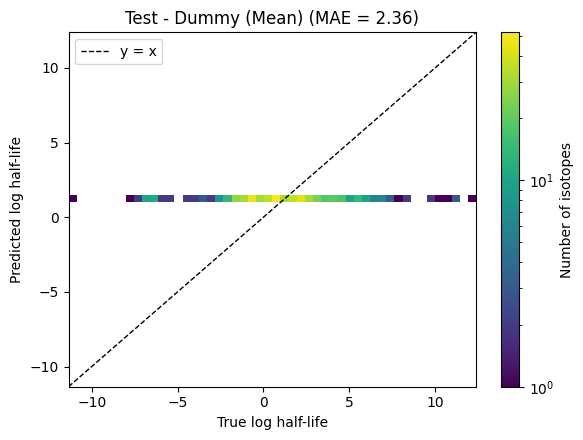

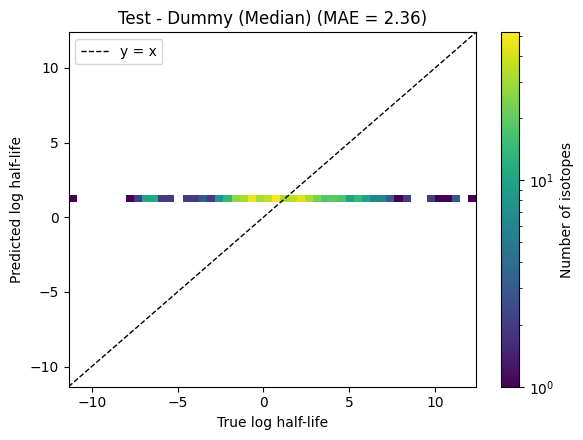

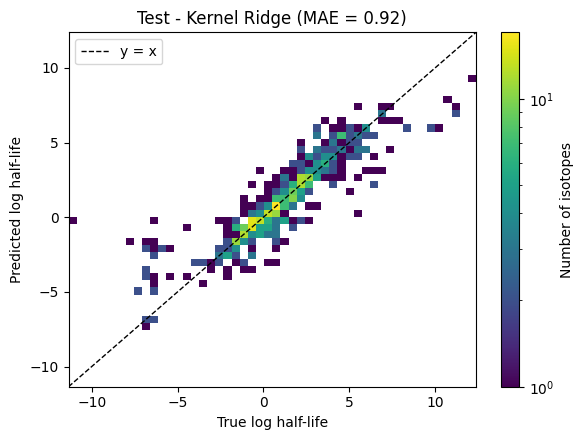

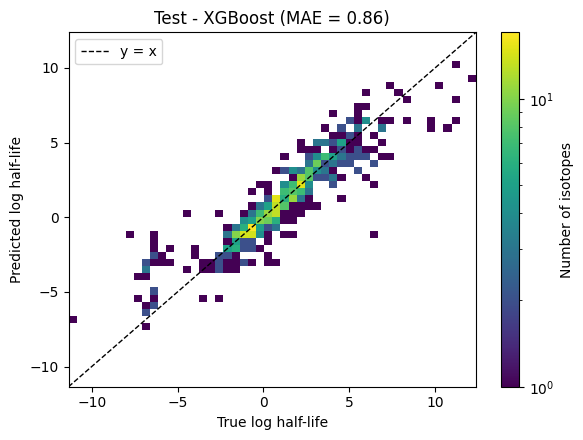

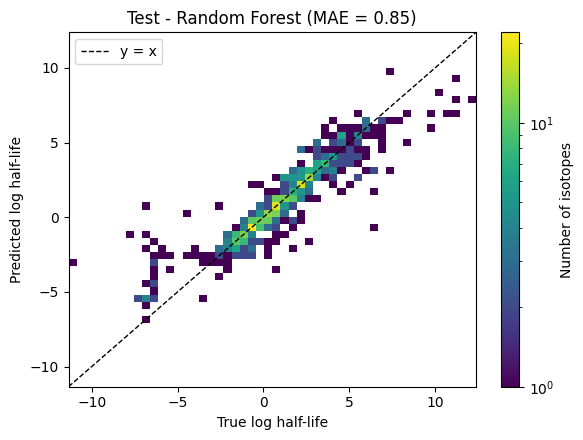

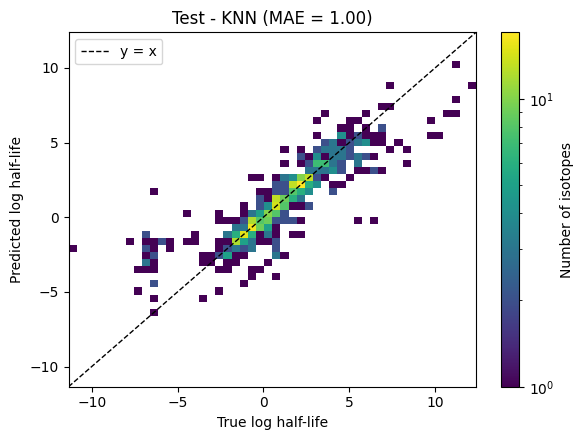

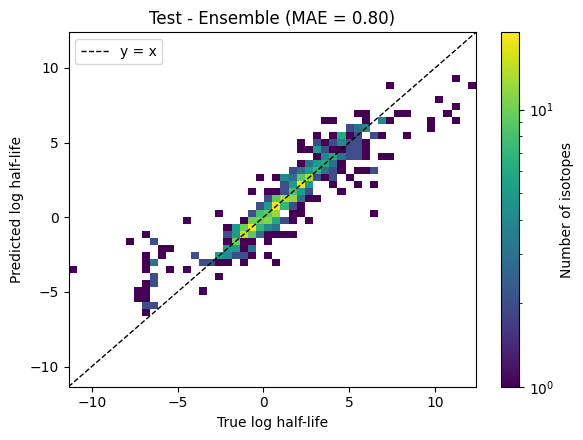

In [17]:
#10. Parity plots of dummy models + best performing models
# Define models
models = {
    'Dummy (Mean)': dummyregressor_mean,
    'Dummy (Median)': dummyregressor_median,
    'Kernel Ridge': krr_optimized,
    'XGBoost': xgb_optimized,
    'Random Forest': rf_optimized,
    'KNN': knn_optimized,
    'Ensemble': ensemble_model
}

# Define parity plot function
def hist_density(y_true, y_pred, xlabel='True log half-life',
                 ylabel='Predicted log half-life', title=None, bins=50):

    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    lims = [
        min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())
    ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create individual figure
    fig, ax = plt.subplots(figsize=(6, 4.5))

    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colour bar
    fig.colorbar(h[3], ax=ax, label='Number of isotopes')

    # Add parity line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# Generate individual parity plots for all models
for name, model in models.items():

    y_pred = model.predict(df_test[features])

    hist_density(
        df_test[TARGET],
        y_pred,
        title=f'Test - {name}'
    )


In [19]:
#11. Summary dataframe of all models 

# Create dataframe containing all test results
all_results_test_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_test,
    'Dummy (Median)': dummyregressor_median_results_test,
    'OLS - Baseline': linear_model_results_test,
    'Ridge Regression': ridge_model_results_test,
    'LASSO': lasso_model_results_test,
    'Polynomial Degree 3': polynomial_deg3_results_test,
    'Kernel Ridge Regression': krr_optimized_results_test,
    'XGBoost': xgb_optimized_results_test,
    'Random Forest': rf_optimized_results_test,
    'K Nearest Neighbors': knn_optimized_results_test,
    'Ensemble Model': ensemble_model_results_test
})

# Transpose dataframe
all_results_test_df = all_results_test_df.T

# Add model categories
all_results_test_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Ensemble',
    'Ensemble',
    'Distance-Based Regression',
    'Ensemble'
])

# Add model names
all_results_test_df.insert(1, 'Model', all_results_test_df.index)

# Reset index
all_results_test_df = all_results_test_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_test_df = all_results_test_df.round(4)


# Display test results
print("\nTEST SET MODEL PERFORMANCE")
display(all_results_test_df)



# Create dataframe containing all training results
all_results_train_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_train,
    'Dummy (Median)': dummyregressor_median_results_train,
    'OLS - Baseline': linear_model_results_train,
    'Ridge Regression': ridge_model_results_train,
    'LASSO': lasso_model_results_train,
    'Polynomial Degree 3': polynomial_deg3_results_train,
    'Kernel Ridge Regression': krr_optimized_results_train,
    'XGBoost': xgb_optimized_results_train,
    'Random Forest': rf_optimized_results_train,
    'K Nearest Neighbors': knn_optimized_results_train,
    'Ensemble Model': ensemble_model_results_train
})

# Transpose dataframe
all_results_train_df = all_results_train_df.T

# Add model categories
all_results_train_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Ensemble',
    'Ensemble',
    'Distance-Based Regression',
    'Ensemble'
])

# Add model names
all_results_train_df.insert(1, 'Model', all_results_train_df.index)

# Reset index
all_results_train_df = all_results_train_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_train_df = all_results_train_df.round(4)

# Display results
print("\nTRAINING SET MODEL PERFORMANCE")
display(all_results_train_df)



TEST SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.3584,10.0656,12.4807,3.1726,-0.0000
1,Dummy Regression,Dummy (Median),2.3565,10.0667,12.4267,3.1728,-0.0001
2,Linear Regression,OLS - Baseline,2.1944,9.1955,12.7089,3.0324,0.0864
3,Linear Regression,Ridge Regression,2.1944,9.1954,12.7085,3.0324,0.0864
4,Linear Regression,LASSO,2.2164,9.3912,13.0417,3.0645,0.0670
5,Polynomial Regression,Polynomial Degree 3,1.5361,6.0806,15.7606,2.4659,0.3959
6,Kernel Regression,Kernel Ridge Regression,0.9157,2.1241,11.3042,1.4574,0.7890
7,Ensemble,XGBoost,0.8559,1.7255,7.6070,1.3136,0.8286
8,Ensemble,Random Forest,0.8461,1.8712,8.1606,1.3679,0.8141
9,Distance-Based Regression,K Nearest Neighbors,1.0006,2.5802,9.3860,1.6063,0.7437



TRAINING SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.4258,10.3292,20.4711,3.2139,0.0000
1,Dummy Regression,Dummy (Median),2.4254,10.3322,20.4171,3.2144,-0.0003
2,Linear Regression,OLS - Baseline,2.2655,9.4157,21.8638,3.0685,0.0884
3,Linear Regression,Ridge Regression,2.2654,9.4157,21.8599,3.0685,0.0884
4,Linear Regression,LASSO,2.2972,9.6245,21.0340,3.1023,0.0682
5,Polynomial Regression,Polynomial Degree 3,1.4078,4.2337,9.2258,2.0576,0.5901
6,Kernel Regression,Kernel Ridge Regression,0.6708,1.0812,8.2907,1.0398,0.8953
7,Ensemble,XGBoost,0.3346,0.2305,3.3457,0.4801,0.9777
8,Ensemble,Random Forest,0.3476,0.3036,5.7430,0.5510,0.9706
9,Distance-Based Regression,K Nearest Neighbors,0.0000,0.0000,0.0000,0.0000,1.0000
